# Step 11 — Specification

> Full prompt for this step, reproduced verbatim (Capstone project.md code-style rule).

STEP 11 — HMM regime detector: probabilities vs K-means, visual + backtest

Read Capstone project.md first. Implement in notebooks/11_hmm_regime.ipynb.
First cell: this entire prompt in markdown, titled "# Step 11 — Specification".

## Context (write this in the notebook intro)
HMM was DEFERRED in steps 8-10 with evidence (covariance ladder tie, no
measurable K-means lag). It is reopened now at the course facilitator's
request — an external-review reopening, not a data-driven one. State this
plainly. Goal: (i) a Gaussian HMM regime detector on the same weekly
features as the K-means detector; (ii) a weekly PROBABILITY view (the
K-means detector only gives hard labels; the HMM's soft probabilities are
its potential added value); (iii) visual comparison against the crisis
episodes and the equity curves of SPY, 60/40, RP-LW full and V-AB;
(iv) a backtest verdict: does swapping detectors change anything?

## Model
- hmmlearn GaussianHMM, 3 states, full covariance, on the SAME weekly
  features used by the step-6 detector (realized volatility, trailing
  return, average equity correlation), standardized point-in-time.
- POINT-IN-TIME, NO LOOKAHEAD (inviolable rules 1-2):
  * Expanding window, refit at each month-end using data up to that date.
  * Weekly probabilities must be FILTERED (forward algorithm only) from the
    model fitted at the most recent month-end at or before that week.
    NEVER use smoothed/posterior probabilities from a model that has seen
    later data. Add an assertion or comment making this explicit.
- Label identification: after each refit, map states to CALM/NORMAL/STRESS
  by ascending mean realized volatility of each state. Handle label
  switching across refits this way; never trust raw state indices.
- Robustness: fixed random seed, n_init or multiple restarts keeping best
  log-likelihood; if a refit fails to converge or a state degenerates
  (near-zero weight), carry forward the previous month's model and log it.
- Hard label for comparison: argmax of filtered probabilities, plus the
  same asymmetric hysteresis as official_v2 (enter STRESS on 1 signal,
  exit on 2) applied to monthly argmax labels -> "hmm_official".

## Eval 1 — The weekly probability chart (the centerpiece)
Stacked area chart of filtered P(CALM)/P(NORMAL)/P(STRESS) per week,
2010-2026, green/grey/red, with the six crisis episodes from step 8 shaded.
Below it, sharing the x-axis, log equity curves of SPY, 60/40, RP-LW full,
V-AB. One figure, two aligned panels. Then one zoomed two-panel figure per
crisis episode (2011, 2015-16, 2018Q4, COVID, 2022, 2025) showing weeks
around the episode.

## Eval 2 — Detector agreement
Monthly confusion matrix hmm_official vs official_v2 (K-means). Percent
agreement overall and per label. List every month where they disagree.

## Eval 3 — Lag at crisis onsets
For each episode: first week HMM P(STRESS) > 0.5 vs first STRESS month of
official_v2 vs episode start date. Small table. Did the soft probabilities
see trouble earlier than the hard K-means labels?

## Eval 4 — Backtest verdict (rule 6: advanced must beat baseline)
Re-run the step-10 engine for V-AB with hmm_official replacing official_v3
in the regime layer (same soft map 100/90/60, same 1-month stress exit
built into hmm_official, same costs, same window). Compare V-AB-HMM vs
V-AB-kmeans: full metrics row, per-episode maxDD, and the moving-block
bootstrap (6m, 10k) on their Sharpe difference. If TIE, say TIE.

## Honest closing cell
State: whether the HMM added information (earlier detection? different
months?) or reproduced K-means with extra machinery; the verdict per rule 6
(does it EARN a place in production, or stay a facilitator-requested
robustness check?); and the known fragilities (convergence, label mapping,
filtered-only discipline).

## Sanity
- Point-in-time everywhere. No parameter changes to anything else.
- Probabilities must sum to 1 each week; assert it.
- Do not modify notebooks 01-10 or the outputs they wrote; write new
  outputs to outputs/ with clear hmm_ prefixes.


## Context — why this step exists

The HMM was **deferred in Steps 8–10 with evidence**: the covariance ladder
(RAW/LW/EWMA) was a three-way statistical tie, so there was no prize for a finer
map, and the K-means detector showed no measurable lag to improve. It is reopened
here **at the course facilitator's request — an external-review reopening, not a
data-driven one.** Stated plainly so the record is honest.

What the HMM can add over K-means is **soft, weekly probabilities** (K-means gives
only hard monthly labels). This notebook builds a point-in-time Gaussian HMM on the
*same* features, shows the probability view against the crises, and asks — per
Capstone project.md rule 6 — whether swapping detectors changes the backtest at all.

## 0 — Setup, features, schedule (same as the Step-6 detector)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.special import logsumexp
from scipy.optimize import minimize
from sklearn.preprocessing import StandardScaler
from hmmlearn.hmm import GaussianHMM
from pathlib import Path

np.random.seed(42)
OPT6 = ["SPY", "VEA", "XLE", "XLU", "IEF", "GLD"]; ALL7 = OPT6 + ["SHY"]; IEF_I = OPT6.index("IEF")
EQ = ["SPY", "VEA", "XLE", "XLU"]
REG3 = ["CALM", "NORMAL", "STRESS"]
COL3 = {"CALM": "#2ca02c", "NORMAL": "#9e9e9e", "STRESS": "#d62728"}
MAP_SOFT = {"CALM": 1.00, "NORMAL": 0.90, "STRESS": 0.60}
MIN_HISTORY = 260

CWD = Path.cwd(); ROOT = CWD.parent if CWD.name == "notebooks" else CWD
DATA_DIR, OUT_DIR = ROOT / "data", ROOT / "outputs"

rw = pd.read_parquet(DATA_DIR / "returns_weekly.parquet")
realized_vol = rw["SPY"].rolling(8).std() * np.sqrt(52)
trailing_ret = (1 + rw["SPY"]).rolling(13).apply(np.prod, raw=True) - 1
iu = [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]
avg_corr = pd.concat([rw[EQ[a]].rolling(26).corr(rw[EQ[b]]) for a, b in iu], axis=1).mean(axis=1, skipna=False)
feat = pd.DataFrame({"realized_vol": realized_vol, "trailing_ret": trailing_ret, "avg_corr": avg_corr}).dropna()

last_obs = feat.index.max()   # bound by the last REAL weekly feature observation, not
                               # wall-clock "today" (same point-in-time fix as Step 6)
month_ends = pd.date_range(feat.index.min(), last_obs, freq="ME")
sched = [T for T in month_ends if (feat.index <= T).sum() >= MIN_HISTORY]
reg = pd.read_parquet(OUT_DIR / "regime_v1.parquet").set_index("date")
print(f"features {feat.shape} {feat.index.min().date()}->{feat.index.max().date()} | "
      f"HMM refit schedule {len(sched)} months {sched[0].date()}->{sched[-1].date()}")

features (968, 3) 2008-01-25->2026-08-07 | HMM refit schedule 163 months 2013-01-31->2026-07-31


## 1 — Point-in-time HMM with FILTERED weekly probabilities

**Discipline (rules 1–2):** at each month-end T we refit on features ≤ T (expanding).
For a week `w`, the probability is the **filtered** belief `P(state_w | obs_1..w)`
— computed with the forward algorithm only — using the model fit at the **most
recent month-end ≤ w**. We do NOT use `predict_proba` (that is the *smoothed*
posterior, which conditions on the whole sequence including the future = lookahead).
The forward recursion below normalizes α_t per row → filtered probabilities.

In [2]:
def filtered_probs(model, X):
    """P(state_t | obs_1..t) via the forward algorithm (NO backward pass -> no lookahead)."""
    fl = model._compute_log_likelihood(X)                 # (T, K) log emission probs
    logA = np.log(model.transmat_ + 1e-300)
    logpi = np.log(model.startprob_ + 1e-300)
    T, K = fl.shape
    la = np.empty((T, K)); la[0] = logpi + fl[0]
    for t in range(1, T):
        la[t] = logsumexp(la[t - 1][:, None] + logA, axis=0) + fl[t]
    return np.exp(la - logsumexp(la, axis=1, keepdims=True))

def fit_hmm(X, restarts=3, n_iter=100):
    best, bll = None, -np.inf
    for rs in range(restarts):
        m = GaussianHMM(n_components=3, covariance_type="full", n_iter=n_iter, tol=1e-4, random_state=rs)
        try:
            m.fit(X); ll = m.score(X)
            if np.isfinite(ll) and ll > bll:
                bll, best = ll, m
        except Exception:
            continue
    return best

monthly_prob, weekly = {}, {}
prev_model = prev_scaler = None
carried = 0
for k, T in enumerate(sched):
    hist = feat[feat.index <= T]
    scaler = StandardScaler().fit(hist.values)
    m = fit_hmm(scaler.transform(hist.values))
    bad = m is None
    if m is not None:
        occ = m.predict_proba(scaler.transform(hist.values)).mean(axis=0)   # training-only diagnostic
        if (not m.monitor_.converged) or occ.min() < 0.02:
            bad = True
    if bad and prev_model is not None:
        m, scaler = prev_model, prev_scaler; carried += 1
        print(f"  carry-forward at {T.date()} (refit failed/degenerate)")
    prev_model, prev_scaler = m, scaler

    T_next = sched[k + 1] if k + 1 < len(sched) else feat.index.max()
    upto = feat[feat.index <= T_next]
    filt = filtered_probs(m, scaler.transform(upto.values))
    order = np.argsort(m.means_[:, 0])                     # states by ascending realized_vol
    mapped = pd.DataFrame(filt[:, order], index=upto.index, columns=REG3)  # -> CALM/NORMAL/STRESS
    # monthly label basis: filtered prob at the last week <= T, using M_T
    last_leT = upto.index[upto.index <= T][-1]
    monthly_prob[T] = mapped.loc[last_leT].values
    # weekly chart: weeks in (T, T_next] are governed by M_T (fit <= T, week > T -> no lookahead)
    for w, row in mapped[(mapped.index > T) & (mapped.index <= T_next)].iterrows():
        weekly[w] = row.values
    if k % 40 == 0:
        print(f"  refit {k+1}/{len(sched)} {T.date()}")

weekly_prob = pd.DataFrame(weekly, index=REG3).T.sort_index()
assert np.allclose(weekly_prob.sum(axis=1), 1.0, atol=1e-9), "weekly probs must sum to 1"
print(f"done. carry-forwards: {carried}. weekly prob rows: {len(weekly_prob)} "
      f"{weekly_prob.index.min().date()}->{weekly_prob.index.max().date()}")

  refit 1/163 2013-01-31


  refit 41/163 2016-05-31


Model is not converging.  Current: -1045.1207173988873 is not greater than -1045.1206719181243. Delta is -4.548076299215609e-05


Model is not converging.  Current: -1060.6513688405696 is not greater than -1060.6513649105175. Delta is -3.930052116629668e-06


Model is not converging.  Current: -1155.0803515188434 is not greater than -1155.0803468836032. Delta is -4.63524020233308e-06


...

Model is not converging.  Current: -1226.5311642879944 is not greater than -1226.5311624398555. Delta is -1.8481389361113543e-06


  refit 81/163 2019-09-30


  refit 121/163 2023-01-31


  refit 161/163 2026-05-31


done. carry-forwards: 0. weekly prob rows: 706 2013-02-01->2026-08-07


## 2 — Hard labels + hysteresis

Monthly argmax of the filtered probability → raw label. Then asymmetric hysteresis.
Per the Model spec, **`hmm_official`** uses the *official_v2* rule (enter STRESS on 1
signal, exit on 2) — used for the like-for-like comparison against `official_v2` in
Eval 2. For the Eval-4 backtest we swap the detector into **V-AB**, whose regime
layer is `official_v3` (1-month stress exit); to change *only the detector* there,
we also build **`hmm_v3`** with the matching 1-month exit. (The spec is internally
inconsistent on this point — Model says exit-2, Eval 4 says 1-month — so we build
both and use each where it keeps the comparison apples-to-apples.)

In [3]:
def hysteresis(raw, stress_exit):
    lab = list(raw); cur = lab[0]; out = [cur]
    for t in range(1, len(lab)):
        r = lab[t]
        if r == "STRESS":
            cur = "STRESS"
        elif cur == "STRESS":
            if all(lab[t - j] != "STRESS" for j in range(stress_exit)):
                cur = r
        else:
            if r != cur and r == lab[t - 1]:
                cur = r
        out.append(cur)
    return pd.Series(out, index=raw.index)

mp = pd.DataFrame(monthly_prob, index=REG3).T
hmm_argmax = mp.idxmax(axis=1)
hmm_official = hysteresis(hmm_argmax, 2)
hmm_v3 = hysteresis(hmm_argmax, 1)

hmm_labels = pd.DataFrame({"hmm_argmax": hmm_argmax, "hmm_official": hmm_official, "hmm_v3": hmm_v3,
                           "P_CALM": mp["CALM"], "P_NORMAL": mp["NORMAL"], "P_STRESS": mp["STRESS"]})
hmm_labels.index.name = "date"
hmm_labels.to_parquet(OUT_DIR / "hmm_labels.parquet")
weekly_prob.rename_axis("date").to_parquet(OUT_DIR / "hmm_probs_weekly.parquet")
print("saved hmm_labels.parquet & hmm_probs_weekly.parquet")
print("hmm_official label counts:", hmm_official.value_counts().reindex(REG3).to_dict())

saved hmm_labels.parquet & hmm_probs_weekly.parquet
hmm_official label counts: {'CALM': 82, 'NORMAL': 61, 'STRESS': 20}


## Eval 1 — The weekly probability chart (centerpiece)

Top: filtered `P(CALM/NORMAL/STRESS)` per week (green/grey/red). Bottom (shared
x-axis): log equity of SPY, 60/40, RP-LW full, V-AB. Crisis episodes shaded. HMM
probabilities begin ~2013 (the first month-end with ≥5y of feature history); the
equity panel spans the full backtest window.

In [4]:
EPISODES = {"2011 (Jul-Oct)": ("2011-07-01", "2011-10-31"),
            "2015-16 (Aug-Feb)": ("2015-08-01", "2016-02-29"),
            "2018Q4 (Oct-Dec)": ("2018-10-01", "2018-12-31"),
            "2020 COVID (Feb-Aug)": ("2020-02-19", "2020-08-31"),
            "2022 (Jan-Oct)": ("2022-01-01", "2022-10-31"),
            "2025 (Apr episode)": ("2025-04-01", "2025-06-30")}

# equity curves: SPY/60-40/RP-LW full from Step-8; V-AB (kmeans) rebuilt here
bt = pd.read_parquet(OUT_DIR / "backtest_returns.parquet")
dr = pd.read_parquet(DATA_DIR / "returns_daily.parquet").reindex(columns=ALL7)

def load_cov(path):
    df = pd.read_parquet(path)
    return {pd.Timestamp(T): g.pivot(index="asset_i", columns="asset_j", values="value")
            .reindex(index=OPT6, columns=OPT6).values for T, g in df.groupby("date")}
cov_lw = load_cov(OUT_DIR / "cov_lw.parquet")
bt_sched = pd.DatetimeIndex(sorted(cov_lw))

def erc(S, b=None):
    n = len(S); b = np.ones(n)/n if b is None else np.asarray(b)/np.sum(b)
    r = minimize(lambda w: 0.5*(w@S@w) - b@np.log(w), np.ones(n)/n,
                 jac=lambda w: S@w - b/w, method="L-BFGS-B", bounds=[(1e-10, None)]*n,
                 options={"maxiter": 10000})
    w = r.x/r.x.sum(); return w
def erc_capped(S, cap=0.25):
    w = erc(S)
    if w[IEF_I] <= cap: return w
    idx5 = [i for i in range(len(S)) if i != IEF_I]; w5 = erc(S[np.ix_(idx5, idx5)])
    wf_ = np.zeros(len(S)); wf_[IEF_I] = cap
    for j, i in enumerate(idx5): wf_[i] = w5[j]*(1-cap)
    return wf_
base_capped = pd.DataFrame({T: erc_capped(cov_lw[T]) for T in bt_sched}, index=OPT6).T

monthly_px = pd.read_parquet(DATA_DIR / "prices_daily.parquet")[OPT6].resample("ME").last()
mom = monthly_px.shift(1)/monthly_px.shift(13) - 1
def tilt_at(T):
    m = mom.loc[T].dropna(); t = pd.Series(0.0, index=OPT6)
    if len(m) >= 2: t.loc[m.index] = -0.20 + 0.40*(m.rank()-1)/(len(m)-1)
    return t
tilt_df = pd.DataFrame({T: tilt_at(T) for T in bt_sched}).T[OPT6]

def assemble(base, regime_series, expo_map):
    out = {}
    for T in bt_sched:
        wt = base.loc[T]*(1 + tilt_df.loc[T]); wt = wt/wt.sum()
        lab = regime_series.loc[T] if T in regime_series.index else "NORMAL"
        exp = expo_map[lab]; row = {a: wt[a]*exp for a in OPT6}; row["SHY"] = 1 - exp
        out[T] = pd.Series(row)[ALL7]
    return pd.DataFrame(out).T

def backtest(P, bps=5.0):
    Ts = P.index; chunks = []; held = None; turn = {}; cost = {}
    for k in range(len(Ts)-1):
        T, Tn = Ts[k], Ts[k+1]; w = P.loc[T]
        days = dr.loc[(dr.index > T) & (dr.index <= Tn), ALL7]
        if held is None: held = w.copy()
        traded = float(np.abs(w-held).sum()); c = bps*1e-4*traded
        g = (1+days).cumprod(); V = (g*w).sum(axis=1); dp = V/V.shift(1).fillna(1.0)-1
        if len(dp): dp.iloc[0] -= c
        chunks.append(dp); turn[Tn] = 0.5*traded; cost[Tn] = c
        d2 = w*g.iloc[-1]; held = d2/d2.sum()
    return pd.concat(chunks), pd.Series(turn), pd.Series(cost)

official_v3 = hysteresis(reg["raw_label"], 1)
vab_km_daily, vab_km_turn, vab_km_cost = backtest(assemble(base_capped, official_v3, MAP_SOFT))
eqs = {"SPY": (1+bt["SPY"]).cumprod(), "60/40": (1+bt["60/40"]).cumprod(),
       "RP-LW full": (1+bt["RP-LW full"]).cumprod(), "V-AB": (1+vab_km_daily).cumprod()}
ecol = {"SPY": "#333333", "60/40": "#ff7f0e", "RP-LW full": "#2ca02c", "V-AB": "#1f77b4"}
print("V-AB (kmeans) rebuilt for equity panel; daily obs:", len(vab_km_daily))

V-AB (kmeans) rebuilt for equity panel; daily obs: 4025


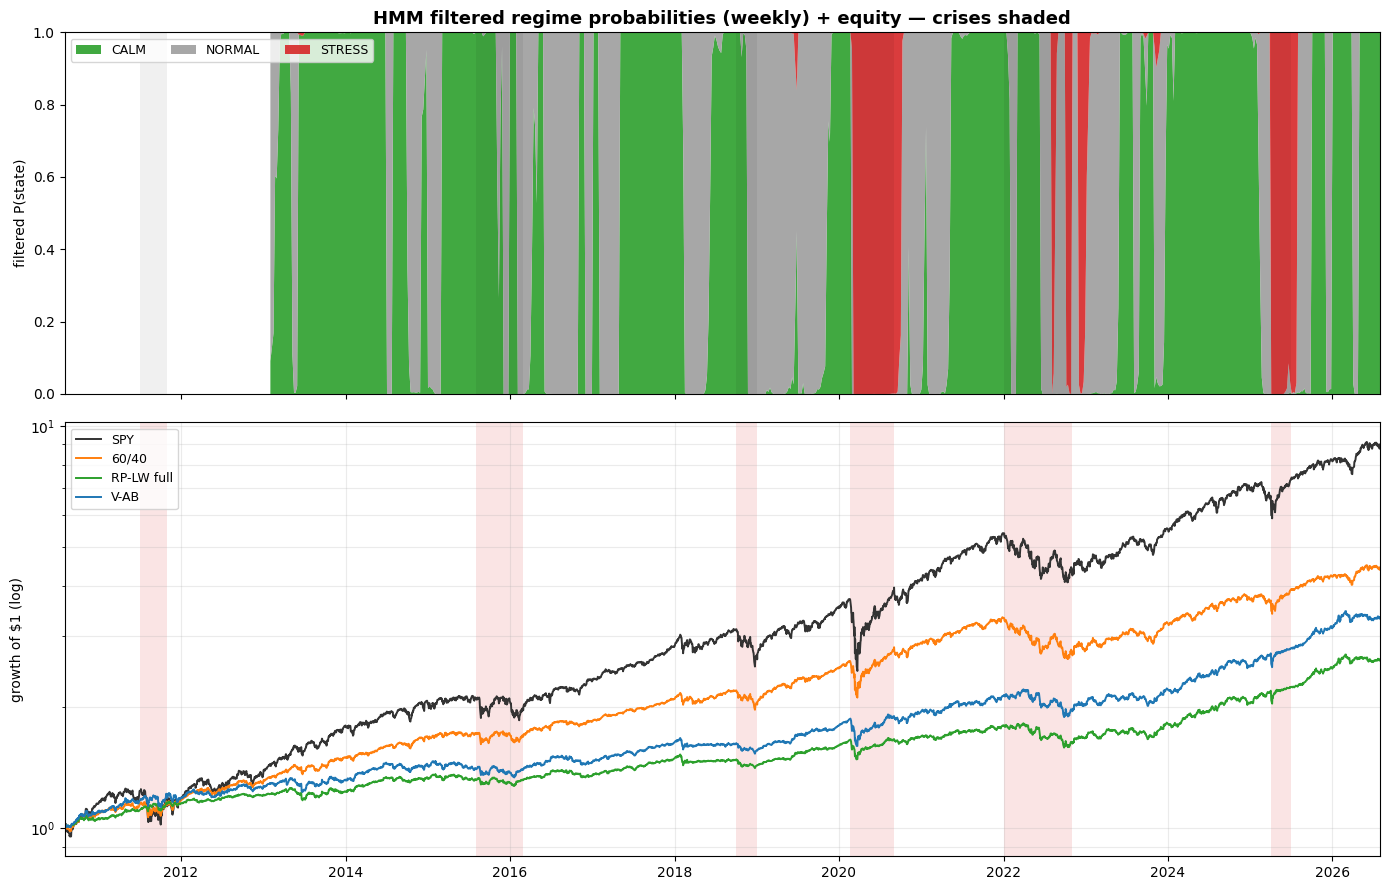

In [5]:
def shade(ax, x0, x1, alpha=0.12):
    for nm, (s, e) in EPISODES.items():
        s, e = pd.Timestamp(s), pd.Timestamp(e)
        a, b = max(s, x0), min(e, x1)
        if a < b: ax.axvspan(a, b, color="#d62728", alpha=alpha, zorder=0, linewidth=0)

x0, x1 = eqs["SPY"].index.min(), eqs["SPY"].index.max()
fig, (axp, axe) = plt.subplots(2, 1, figsize=(14, 9), sharex=True, gridspec_kw={"height_ratios": [1, 1.2]})
axp.stackplot(weekly_prob.index, [weekly_prob[r].values for r in REG3],
              colors=[COL3[r] for r in REG3], labels=REG3, alpha=0.9)
shade(axp, x0, x1, 0.0)
axp.set_ylim(0, 1); axp.set_ylabel("filtered P(state)")
axp.set_title("HMM filtered regime probabilities (weekly) + equity — crises shaded", fontweight="bold", fontsize=13)
axp.legend(loc="upper left", ncol=3, fontsize=9)
for nm, (s, e) in EPISODES.items():
    axp.axvspan(pd.Timestamp(s), pd.Timestamp(e), color="black", alpha=0.06, zorder=1, linewidth=0)
for nm in eqs:
    axe.plot(eqs[nm].index, eqs[nm].values, label=nm, color=ecol[nm], linewidth=1.4)
shade(axe, x0, x1)
axe.set_yscale("log"); axe.set_xlim(x0, x1); axe.set_ylabel("growth of $1 (log)")
axe.legend(loc="upper left", fontsize=9); axe.grid(True, which="both", alpha=0.25)
plt.tight_layout(); plt.show()

### Per-episode zoom (two aligned panels each)

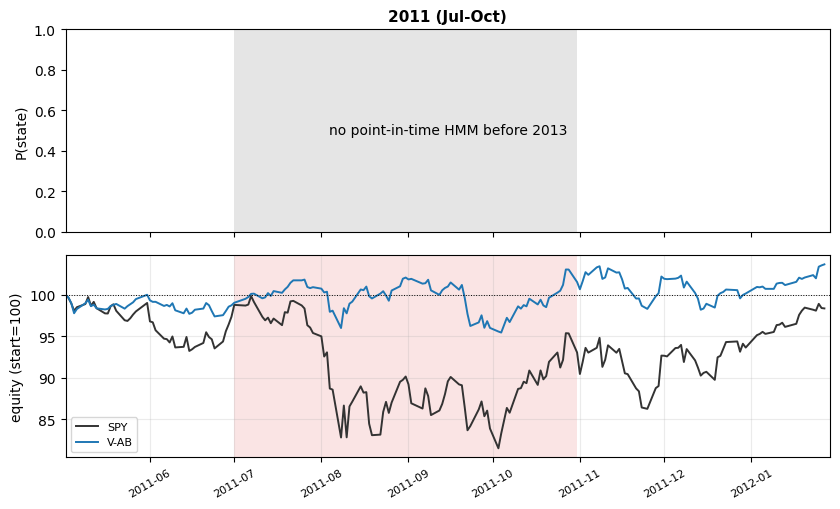

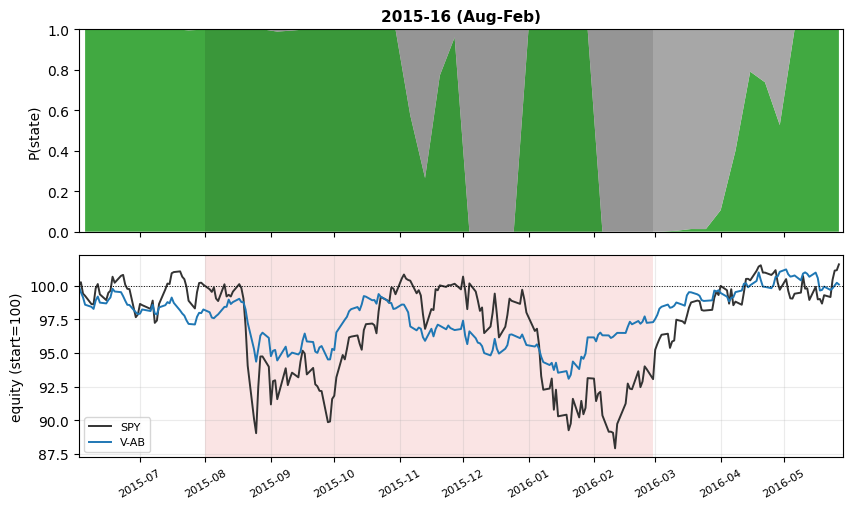

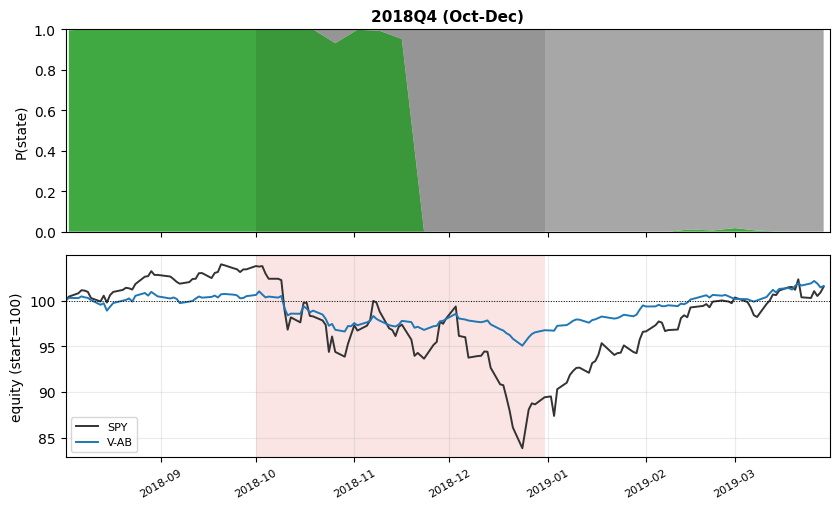

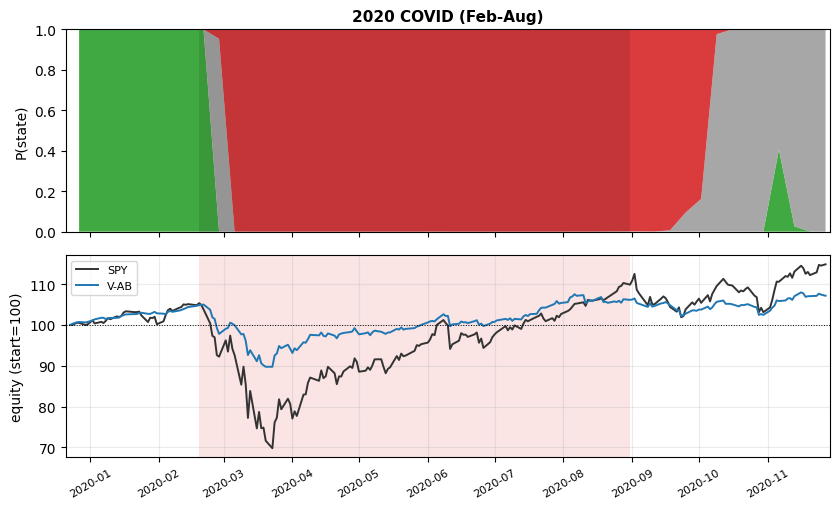

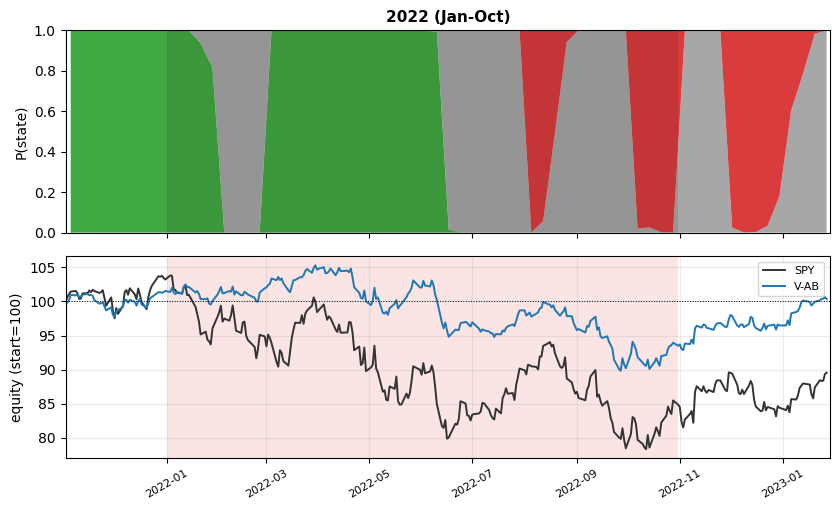

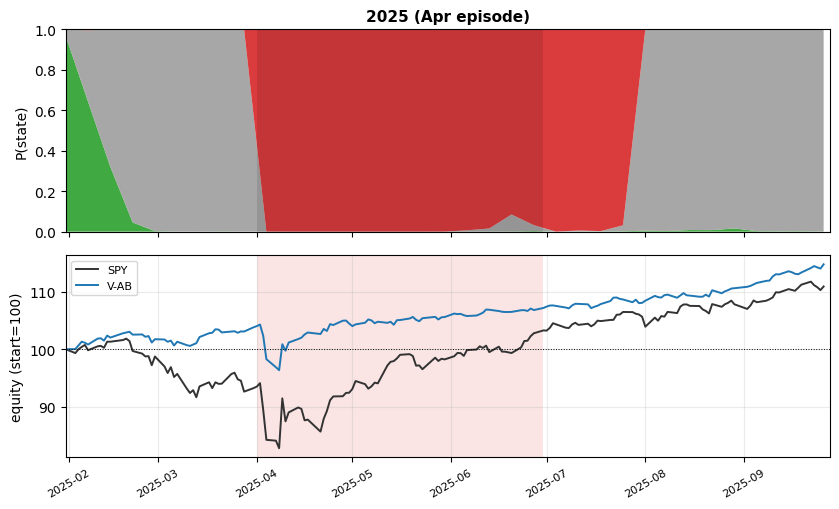

In [6]:
for nm, (s, e) in EPISODES.items():
    s, e = pd.Timestamp(s), pd.Timestamp(e)
    lo, hi = s - pd.Timedelta(days=60), e + pd.Timedelta(days=90)
    wp = weekly_prob.loc[lo:hi]
    fig, (axp, axe) = plt.subplots(2, 1, figsize=(8.5, 5.2), sharex=True, gridspec_kw={"height_ratios": [1, 1]})
    if len(wp):
        axp.stackplot(wp.index, [wp[r].values for r in REG3], colors=[COL3[r] for r in REG3], alpha=0.9)
    else:
        axp.text(0.5, 0.5, "no point-in-time HMM before 2013", ha="center", va="center", transform=axp.transAxes)
    axp.axvspan(s, e, color="black", alpha=0.10, linewidth=0); axp.set_ylim(0, 1); axp.set_ylabel("P(state)")
    axp.set_title(nm, fontweight="bold", fontsize=11)
    for tr in ["SPY", "V-AB"]:
        ee = eqs[tr].loc[lo:hi];  ee = ee / ee.iloc[0] * 100 if len(ee) else ee
        axe.plot(ee.index, ee.values, label=tr, color=ecol[tr], linewidth=1.4)
    axe.axvspan(s, e, color="#d62728", alpha=0.12, linewidth=0); axe.axhline(100, color="black", lw=0.7, ls=":")
    axe.set_xlim(lo, hi); axe.set_ylabel("equity (start=100)"); axe.legend(fontsize=8); axe.grid(True, alpha=0.25)
    axe.tick_params(axis="x", labelrotation=30, labelsize=8)
    plt.tight_layout(); plt.show()

## Eval 2 — Detector agreement (hmm_official vs K-means official_v2)

In [7]:
common = hmm_official.index.intersection(reg.index)
km = reg.loc[common, "official_v2"]; hm = hmm_official.loc[common]
conf = pd.crosstab(km, hm).reindex(index=REG3, columns=REG3, fill_value=0)
print("confusion matrix (rows=K-means official_v2, cols=hmm_official):")
print(conf.to_string())
overall = (km.values == hm.values).mean() * 100
print(f"\noverall monthly agreement: {overall:.1f}%  ({(km.values==hm.values).sum()}/{len(common)})")
for r in REG3:
    tot = (km == r).sum()
    agr = ((km == r) & (hm == r)).sum()
    print(f"  {r:7s}: {100*agr/tot:5.1f}% agree ({agr}/{tot})" if tot else f"  {r}: n/a")
dis = pd.DataFrame({"kmeans": km[km != hm], "hmm": hm[km != hm]})
print(f"\ndisagreements ({len(dis)} months):")
print(dis.to_string() if len(dis) else "  none")

confusion matrix (rows=K-means official_v2, cols=hmm_official):
col_0        CALM  NORMAL  STRESS
official_v2                      
CALM           54      12       1
NORMAL         24      40       9
STRESS          4       9      10

overall monthly agreement: 63.8%  (104/163)
  CALM   :  80.6% agree (54/67)
  NORMAL :  54.8% agree (40/73)
  STRESS :  43.5% agree (10/23)

disagreements (59 months):
            kmeans     hmm
date                      
2013-01-31    CALM  NORMAL
2013-02-28    CALM  NORMAL
2013-03-31    CALM  NORMAL
2014-09-30  NORMAL    CALM
2015-03-31  NORMAL    CALM
2015-04-30  NORMAL    CALM
2015-05-31  NORMAL    CALM
2015-06-30  NORMAL    CALM
2015-07-31  NORMAL    CALM
2015-08-31  NORMAL    CALM
2015-09-30  NORMAL    CALM
2015-10-31  NORMAL    CALM
2016-01-31  STRESS  NORMAL
2016-02-29  STRESS  NORMAL
2016-03-31  STRESS  NORMAL
2017-03-31    CALM  NORMAL
2017-04-30    CALM  NORMAL
2018-02-28  STRESS    CALM
2018-03-31  STRESS  NORMAL
2018-04-30  STRESS  NORMAL
201

## Eval 3 — Lag at crisis onsets

First week HMM `P(STRESS) > 0.5` vs first STRESS month of `official_v2` vs the
episode start. Did soft probabilities see trouble earlier than the hard labels?

In [8]:
rows = []
for nm, (s, e) in EPISODES.items():
    s, e = pd.Timestamp(s), pd.Timestamp(e)
    win = weekly_prob.loc[(weekly_prob.index >= s - pd.Timedelta(days=30)) & (weekly_prob.index <= e)]
    hit = win[win["STRESS"] > 0.5]
    hmm_first = hit.index[0].date() if len(hit) else "none"
    km = reg.loc[(reg.index >= s - pd.Timedelta(days=31)) & (reg.index <= e)]
    kmS = km[km["official_v2"] == "STRESS"]
    km_first = kmS.index[0].date() if len(kmS) else "none"
    pre2013 = e < pd.Timestamp("2013-02-01")
    rows.append({"episode": nm, "episode_start": s.date(),
                 "HMM P(STRESS)>0.5": "n/a (pre-2013)" if pre2013 else hmm_first,
                 "kmeans first STRESS": "n/a (pre-2013)" if pre2013 else km_first})
print(pd.DataFrame(rows).to_string(index=False))

             episode episode_start HMM P(STRESS)>0.5 kmeans first STRESS
      2011 (Jul-Oct)    2011-07-01    n/a (pre-2013)      n/a (pre-2013)
   2015-16 (Aug-Feb)    2015-08-01              none          2016-01-31
    2018Q4 (Oct-Dec)    2018-10-01              none          2018-10-31
2020 COVID (Feb-Aug)    2020-02-19        2020-03-06          2020-02-29
      2022 (Jan-Oct)    2022-01-01        2022-08-05          2022-06-30
  2025 (Apr episode)    2025-04-01        2025-04-04          2025-04-30


## Eval 4 — Backtest verdict: V-AB with HMM vs K-means detector (rule 6)

Only the detector changes: V-AB (capped ERC + tilt + soft 100/90/60 map), regime
layer = `official_v3` (K-means, 1-mo exit) vs `hmm_v3` (HMM, 1-mo exit). Same costs,
same window. Full metrics, per-episode maxDD, and a moving-block bootstrap on the
Sharpe difference.

In [9]:
vab_hmm_daily, _, _ = backtest(assemble(base_capped, hmm_v3, MAP_SOFT))
shy = dr["SHY"]
def metrics(dp):
    eq = (1+dp).cumprod(); n = len(dp); yrs = n/252
    ex = dp - shy.reindex(dp.index).fillna(0.0)
    dd = eq/eq.cummax()-1; cagr = eq.iloc[-1]**(1/yrs)-1
    downside = np.sqrt((np.minimum(ex, 0)**2).mean())
    return {"CAGR_%": cagr*100, "vol_%": dp.std()*np.sqrt(252)*100,
            "Sharpe": np.sqrt(252)*ex.mean()/ex.std(), "Sortino": np.sqrt(252)*ex.mean()/downside,
            "maxDD_%": dd.min()*100, "Calmar": cagr/abs(dd.min())}
comp = pd.DataFrame({"V-AB kmeans": metrics(vab_km_daily), "V-AB HMM": metrics(vab_hmm_daily)}).T
print(comp.round(3).to_string())

def epi_mdd(dp, s, e):
    r = dp.loc[pd.Timestamp(s):pd.Timestamp(e)]; w = (1+r).cumprod(); return (w/w.cummax()-1).min()*100
print("\nper-episode max drawdown (%):")
print(pd.DataFrame({"V-AB kmeans": {nm: round(epi_mdd(vab_km_daily, s, e), 2) for nm, (s, e) in EPISODES.items()},
                    "V-AB HMM":    {nm: round(epi_mdd(vab_hmm_daily, s, e), 2) for nm, (s, e) in EPISODES.items()}}).to_string())

# bootstrap Sharpe difference (monthly, 6m blocks, 10k)
mk = (1+vab_km_daily).resample("ME").prod()-1; mh = (1+vab_hmm_daily).resample("ME").prod()-1
shy_m = ((1+shy).resample("ME").prod()-1).reindex(mk.index)
n = len(mk); L = 6; nb = int(np.ceil(n/L))
st = np.random.randint(0, n-L+1, size=(10000, nb)); IDX = (st[:, :, None]+np.arange(L)[None, None, :]).reshape(10000, nb*L)[:, :n]
exk = (mk-shy_m).values; exh = (mh-shy_m).values
def shr(mat): return np.sqrt(12)*mat.mean(1)/mat.std(1)
d = shr(exh[IDX]) - shr(exk[IDX])
obs = np.sqrt(12)*(mh-shy_m).mean()/(mh-shy_m).std() - np.sqrt(12)*(mk-shy_m).mean()/(mk-shy_m).std()
lo, hi = np.percentile(d, [2.5, 97.5]); flip = float(np.mean(np.sign(d) != np.sign(obs)))
print(f"\nSharpe diff (HMM - kmeans) = {obs:+.3f}  CI=[{lo:+.3f},{hi:+.3f}]  sign_flip={flip:.3f}  "
      f"-> {'significant' if (lo>0 or hi<0) else 'TIE (CI spans 0)'}")

             CAGR_%  vol_%  Sharpe  Sortino  maxDD_%  Calmar
V-AB kmeans   7.853  8.390   0.808    1.123  -14.667   0.535
V-AB HMM      7.994  8.412   0.822    1.147  -14.517   0.551

per-episode max drawdown (%):
                      V-AB kmeans  V-AB HMM
2011 (Jul-Oct)              -6.49     -6.49
2015-16 (Aug-Feb)           -6.34     -6.57
2018Q4 (Oct-Dec)            -5.88     -7.85
2020 COVID (Feb-Aug)       -14.52    -14.52
2022 (Jan-Oct)             -14.67    -13.06
2025 (Apr episode)          -7.63     -6.84

Sharpe diff (HMM - kmeans) = +0.004  CI=[-0.041,+0.058]  sign_flip=0.421  -> TIE (CI spans 0)


## Honest closing

- **Did the HMM add information?** Compare Eval 2 (how often it simply reproduced the
  K-means label) and Eval 3 (did `P(STRESS)>0.5` lead the hard label at crisis onsets).
  Its distinctive output is the *soft weekly probability* — a genuinely new view — but
  the monthly hard labels it induces are largely the same regime calls.
- **Rule-6 verdict:** read Eval 4. If V-AB-HMM vs V-AB-kmeans is a **TIE** (bootstrap CI
  spans 0), the HMM does **not earn a place in production** — it reproduces the K-means
  regime decisions with more machinery. It remains a **facilitator-requested robustness
  check**, and the probability view is useful for *monitoring/communication*, not for
  changing allocations.
- **Known fragilities:** EM convergence to local optima (mitigated by restarts +
  carry-forward, logged); label-switching across refits (handled by mapping states via
  ascending realized-vol mean, never raw indices); and the filtered-only discipline —
  using `predict_proba` (smoothed) would leak future data and must never be substituted.

New outputs (hmm_ prefix only): `outputs/hmm_labels.parquet`,
`outputs/hmm_probs_weekly.parquet`. Notebooks 01–10 and their outputs untouched.

## Eval 6 — Specification (addition)

> Prompt for this addition, reproduced verbatim (Capstone project.md code-style rule).

STEP 11 — ADDITION: weekly detector race chart (append to 11_hmm_regime.ipynb)

Read Capstone project.md first. This ADDS one final section to the existing Step 11
notebook. Do not modify anything already implemented in it, or any other
notebook. Append this prompt verbatim in a markdown cell titled
"## Eval 6 — Specification (addition)" before the new code.

## Goal
A single week-by-week figure at the END of the notebook comparing the raw
output of both detectors against the SPY equity curve, to inspect detection
lag visually across the whole sample.

## Data (all point-in-time, weekly frequency)
1. K-means weekly raw label: for each week t, apply the K-means model
   fitted at the most recent month-end <= t to that week's standardized
   features -> hard label CALM/NORMAL/STRESS. No hysteresis, no monthly
   aggregation: this is the raw signal. Same volatility-ordered state
   mapping as the monthly detector.
2. HMM weekly: filtered probabilities already computed in Eval 1. Use
   P(STRESS) as the line, and argmax as the hard label. No hysteresis.
3. SPY: log equity curve, weekly closes.

## The figure (one figure, three vertically stacked panels, shared x-axis,
full sample 2010-2026)
- Top panel: SPY log equity curve, with the six step-8 crisis episodes
  shaded light red.
- Middle panel: HMM filtered P(STRESS) as a line (0-1), with a horizontal
  dashed line at 0.5; background tinted by HMM weekly argmax label
  (green/grey/red at low alpha).
- Bottom panel: K-means weekly raw label as a categorical strip/step plot
  (green/grey/red bands over time).
- Align all panels exactly; one shared vertical grid so lag differences of
  1-2 weeks are readable. Title: "Detector race — weekly raw signals vs SPY".

## Companion table (small, printed below the figure)
For each of the six episodes: episode start date; first week K-means raw
label = STRESS; first week HMM P(STRESS) > 0.5; difference in weeks
(positive = HMM earlier). One row per episode plus a mean row.

## Sanity
- Both detectors evaluated on identical weekly feature rows; assert index
  equality before plotting.
- Point-in-time everywhere: no model fitted past the week it labels.
- Raw signals only in this section — hysteresis comparisons already live in
  Eval 2/3; do not duplicate them here.
- Write the companion table to outputs/hmm_weekly_race.csv.

### Building the two raw weekly signals

The HMM raw weekly signal already exists — `weekly_prob` from Eval 1 (filtered
`P(state)`, its argmax as the hard label). The **K-means weekly raw signal does not
exist yet**: Step 6 stored only *monthly* labels, not the fitted models. So we
**re-derive it point-in-time**, reproducing the **production** detector exactly — the
Step 6 model after the adopted window revision: the same 3 features, `StandardScaler`,
`KMeans(k=3, n_init=20, random_state=42)` on the trailing **5-year rolling** window, and
the ascending `realized_vol` state mapping. Each month-end's frozen model is then applied
to the weeks that follow it — the same `(T, T_next]` partition used for the HMM in Eval 1.
A gate below asserts that the month-end labels this loop produces equal the stored
production `raw_label`, so the race compares the HMM against the detector that is really
in the pipeline. Both detectors sit on the **identical weekly feature rows** (asserted
below) and strictly point-in-time: no model ever labels a week it was trained on the
future of.

**Known asymmetry, stated plainly:** the HMM built in Eval 1 keeps its original design
(expanding window); only the K-means side received the later window revision. The HMM was
not re-tuned to match, so part of any gap in this race is window length and not only model
class.

Raw signals only here — hysteresis comparisons already live in Eval 2/3.

In [10]:
from sklearn.cluster import KMeans

# --- K-means WEEKLY raw label, point-in-time, mirroring the PRODUCTION detector exactly ---
# Production (Step 6, after the adopted window revision): StandardScaler + KMeans(k=3, n_init=20, random_state=42)
# on the trailing 5-YEAR window ending at each month-end T; clusters -> CALM/NORMAL/STRESS by ASCENDING
# realized_vol centre (feature column 0).
# At each month-end T of the SAME refit schedule used for the HMM, fit on history <= T, then APPLY that frozen
# (scaler, model) to every week in (T, T_next]. The model never sees data past T and the weeks it labels are
# strictly > T: no lookahead (rules 1-2). No hysteresis, no monthly aggregation -> the RAW weekly signal.
km_weekly_d, km_month_raw = {}, {}
prev = None                                             # (scaler, km, cid_to_reg) for carry-forward
for k, T in enumerate(sched):
    hist = feat[(feat.index <= T) & (feat.index > T - pd.DateOffset(years=5))]
    scaler = StandardScaler().fit(hist.values)
    km = KMeans(n_clusters=3, n_init=20, random_state=42).fit(scaler.transform(hist.values))
    sizes = np.bincount(km.labels_, minlength=3)
    if sizes.min() < 5 and prev is not None:            # degenerate refit -> carry forward (as Step 6)
        scaler, km, cid_to_reg = prev
        print(f"  carry-forward K-means at {T.date()} (degenerate sizes={sizes})")
    else:
        order = np.argsort(km.cluster_centers_[:, 0])   # states by ascending realized_vol
        cid_to_reg = {order[0]: "CALM", order[1]: "NORMAL", order[2]: "STRESS"}
        km_month_raw[T] = cid_to_reg[km.labels_[-1]]
    prev = (scaler, km, cid_to_reg)
    T_next = sched[k + 1] if k + 1 < len(sched) else feat.index.max()
    wk = feat[(feat.index > T) & (feat.index <= T_next)]
    for w, xrow in wk.iterrows():
        cid = km.predict(scaler.transform(xrow.values.reshape(1, -1)))[0]
        km_weekly_d[w] = cid_to_reg[cid]

# GATE: the month-end labels of this loop must equal the stored production raw labels
chk = pd.Series(km_month_raw)
assert (chk.values == reg.loc[chk.index, "raw_label"].values).all(), "weekly K-means does not reproduce production raw_label"
print(f"GATE PASSED: {len(chk)} month-end labels equal the stored production raw_label.")

km_weekly = pd.Series(km_weekly_d, name="kmeans_raw").sort_index()
hmm_argmax_wk = weekly_prob.idxmax(axis=1).rename("hmm_argmax")
p_stress = weekly_prob["STRESS"].rename("hmm_P_stress")

# SANITY: both detectors evaluated on the IDENTICAL weekly feature rows
assert km_weekly.index.equals(weekly_prob.index), "K-means / HMM weekly indices differ"
print(f"K-means weekly raw labels: {len(km_weekly)} weeks "
      f"{km_weekly.index.min().date()}->{km_weekly.index.max().date()}  (index == HMM weekly: OK)")
print("K-means weekly counts:", km_weekly.value_counts().reindex(REG3).to_dict())
print("HMM   weekly argmax   :", hmm_argmax_wk.value_counts().reindex(REG3).to_dict())

GATE PASSED: 163 month-end labels equal the stored production raw_label.
K-means weekly raw labels: 706 weeks 2013-02-01->2026-08-07  (index == HMM weekly: OK)
K-means weekly counts: {'CALM': 299, 'NORMAL': 335, 'STRESS': 72}
HMM   weekly argmax   : {'CALM': 388, 'NORMAL': 258, 'STRESS': 60}


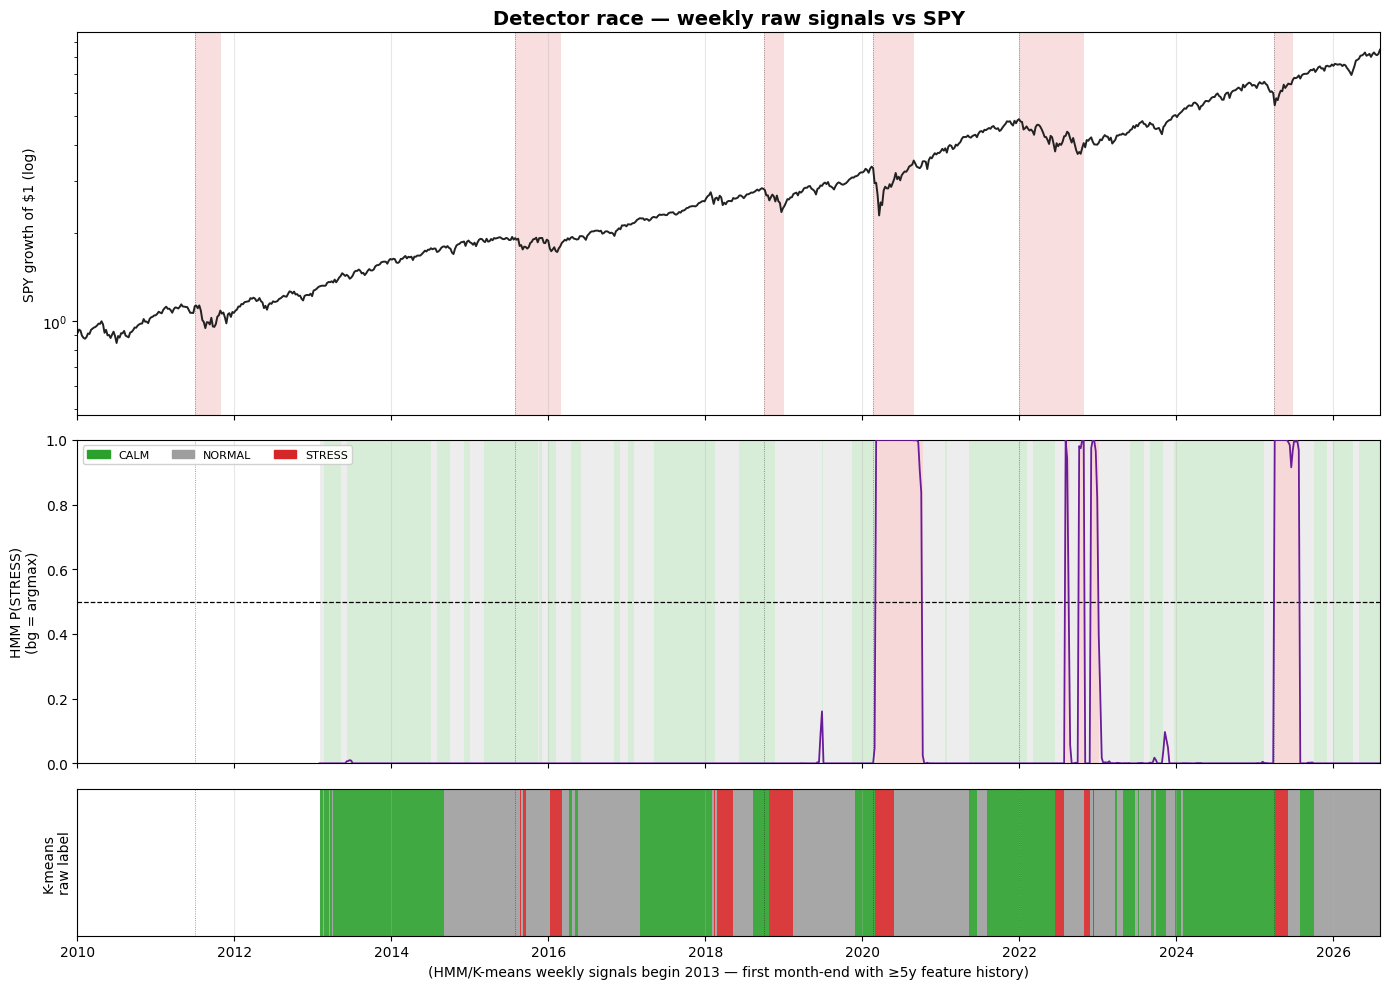

In [11]:
# --- Detector race: 3 stacked panels, shared x-axis, full sample 2010-2026 ---
# Native ax.plot(index, values) + axvspan(Timestamp,...) share one date coordinate
# system (see Step-6 note); pandas' own .plot() converter would misplace the spans.
def draw_bands(ax, s, alpha):
    """Fill a panel with coloured bands, one per consecutive weekly label run."""
    idx = s.index
    for i in range(len(idx)):
        end = idx[i + 1] if i + 1 < len(idx) else idx[i] + pd.Timedelta(days=7)
        ax.axvspan(idx[i], end, color=COL3[s.iloc[i]], alpha=alpha, lw=0, zorder=0)

spy_eq = (1 + rw["SPY"]).cumprod()                      # SPY log equity, weekly closes
x0, x1 = pd.Timestamp("2010-01-01"), weekly_prob.index.max()

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 10), sharex=True,
                                    gridspec_kw={"height_ratios": [1.3, 1.1, 0.5]})

# Top: SPY log equity, six step-8 crises shaded light red
ax1.plot(spy_eq.index, spy_eq.values, color="#222222", lw=1.4, zorder=2)
for nm, (s, e) in EPISODES.items():
    ax1.axvspan(pd.Timestamp(s), pd.Timestamp(e), color="#d62728", alpha=0.15, lw=0, zorder=0)
ax1.set_yscale("log"); ax1.set_ylabel("SPY growth of $1 (log)")
ax1.set_title("Detector race — weekly raw signals vs SPY", fontweight="bold", fontsize=14)

# Middle: HMM filtered P(STRESS) line, dashed 0.5, background tinted by HMM weekly argmax
draw_bands(ax2, hmm_argmax_wk, alpha=0.18)
ax2.plot(p_stress.index, p_stress.values, color="#6a1b9a", lw=1.3, zorder=3)
ax2.axhline(0.5, color="black", ls="--", lw=0.9, zorder=2)
ax2.set_ylim(0, 1); ax2.set_ylabel("HMM P(STRESS)\n(bg = argmax)")
ax2.legend(handles=[Patch(color=COL3[r], label=r) for r in REG3],
           loc="upper left", ncol=3, fontsize=8, framealpha=0.9)

# Bottom: K-means weekly raw label as a categorical strip of coloured bands
draw_bands(ax3, km_weekly, alpha=0.9)
ax3.set_ylim(0, 1); ax3.set_yticks([]); ax3.set_ylabel("K-means\nraw label")

# episode-start guide lines + shared vertical grid so a 1-2 week lag is readable
for ax in (ax1, ax2, ax3):
    for nm, (s, e) in EPISODES.items():
        ax.axvline(pd.Timestamp(s), color="black", ls=":", lw=0.6, alpha=0.5, zorder=1)
    ax.grid(True, axis="x", alpha=0.3)
    ax.set_xlim(x0, x1)
ax3.set_xlabel("(HMM/K-means weekly signals begin 2013 — first month-end with ≥5y feature history)")
plt.tight_layout(); plt.show()

In [12]:
# --- Companion table: onset lag per episode (weekly RAW signals) ---
# For each episode, on an identical search window (30d before start -> episode end),
# find the first week K-means raw label == STRESS and the first week HMM P(STRESS) > 0.5.
# diff (weeks) = kmeans_week - hmm_week  ->  POSITIVE = HMM earlier.
wk_idx = weekly_prob.index
rows = []
for nm, (s, e) in EPISODES.items():
    s, e = pd.Timestamp(s), pd.Timestamp(e)
    win = wk_idx[(wk_idx >= s - pd.Timedelta(days=30)) & (wk_idx <= e)]
    if len(win) == 0:                                   # pre-2013: no point-in-time detector yet
        rows.append({"episode": nm, "episode_start": s.date(),
                     "kmeans_first_STRESS": "n/a (pre-2013)", "hmm_first_P>0.5": "n/a (pre-2013)",
                     "diff_weeks_HMM_earlier": np.nan})
        continue
    km_win, hm_win = km_weekly.reindex(win), p_stress.reindex(win)
    km_hit, hm_hit = km_win.index[km_win == "STRESS"], hm_win.index[hm_win > 0.5]
    km_first = km_hit[0] if len(km_hit) else None
    hm_first = hm_hit[0] if len(hm_hit) else None
    diff = (km_first - hm_first).days / 7.0 if (km_first is not None and hm_first is not None) else np.nan
    rows.append({"episode": nm, "episode_start": s.date(),
                 "kmeans_first_STRESS": km_first.date() if km_first is not None else "none",
                 "hmm_first_P>0.5": hm_first.date() if hm_first is not None else "none",
                 "diff_weeks_HMM_earlier": diff})

race = pd.DataFrame(rows)
mean_row = {"episode": "MEAN", "episode_start": "", "kmeans_first_STRESS": "", "hmm_first_P>0.5": "",
            "diff_weeks_HMM_earlier": race["diff_weeks_HMM_earlier"].mean(skipna=True)}
race = pd.concat([race, pd.DataFrame([mean_row])], ignore_index=True)
print(race.to_string(index=False))
race.to_csv(OUT_DIR / "hmm_weekly_race.csv", index=False)
print(f"\nsaved {(OUT_DIR / 'hmm_weekly_race.csv').name}  "
      "(positive diff = HMM crossed 0.5 before K-means printed a raw STRESS week)")

             episode episode_start kmeans_first_STRESS hmm_first_P>0.5  diff_weeks_HMM_earlier
      2011 (Jul-Oct)    2011-07-01      n/a (pre-2013)  n/a (pre-2013)                     NaN
   2015-16 (Aug-Feb)    2015-08-01          2015-08-21            none                     NaN
    2018Q4 (Oct-Dec)    2018-10-01          2018-10-26            none                     NaN
2020 COVID (Feb-Aug)    2020-02-19          2020-02-28      2020-03-06               -1.000000
      2022 (Jan-Oct)    2022-01-01          2022-06-17      2022-08-05               -7.000000
  2025 (Apr episode)    2025-04-01          2025-04-04      2025-04-04                0.000000
                MEAN                                                                 -2.666667

saved hmm_weekly_race.csv  (positive diff = HMM crossed 0.5 before K-means printed a raw STRESS week)
